In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
from Bio import SeqIO
import pandas as pd

In [ ]:
#First read in the MCTE info and save the true transposon classes in a dictionary
True_TE = {}
with open("../ClassificationErrorCheck/MCTE_Info.tsv", "r") as MCTE:
    MCTE.readline()
    for line in MCTE:
        l = line.strip().split()
        if l[5] == "RNA":
            True_TE[l[0]] = "1"
        elif l[5] == "DNA":
            True_TE[l[0]] = "2"
        else:
            print("UnexpectedClass:", l[5]) #Check for weird stuff
        #True_TE[l[0]]=Class
        
#Now read the clustering information:
ClusterDict = {}
with open("ClusterTU_MC.clstr", "r") as cluster:
    for line in cluster:
        if line.startswith(">"):
            ClusterID = line.strip()[1:]
            ClusterDict[ClusterID] = ["",[]]
        else:
            l = line.strip().split()
            if l[2].startswith(">Transposon"):
                ClusterDict[ClusterID][1].append(l[2].strip("..."))
            else:
                ClusterDict[ClusterID][0]+=l[2].strip("...")

#Now get the true classification for each transposon
TUDict = {}

for Cluster in ClusterDict:
    MCTE_TE = ClusterDict[Cluster][0][1:].replace("DBGP", "BDGP") #take care of the MCTE typo

    if MCTE_TE not in True_TE:
        print("Missing:", MCTE_TE)
        continue

    TrueClass = True_TE[MCTE_TE]

    if ClusterDict[Cluster][1]:
        for TE in ClusterDict[Cluster][1]:
            TE_ID = TE[1:]

            if TE_ID in TUDict:
                print("WEIRD:", TE_ID)
            else:
                # Create a new list for every TE
                TUDict[TE_ID] = [TrueClass]

print(len(TUDict)) #just test to check for problems

#First read in the TE Classes predicted by TransposonUltimate
gff = "/global/group/research/m_lebh01/TransposonUltimateTE/DmelDK/FinalAnnotations_Transposons.gff3"

with open(gff, "r") as TUClass:
    for line in TUClass:
        if not line.startswith("seq"):
            print("Skipped line")
            continue
        l = line.strip().split("\t")
        TE = "Transposon" + l[8].split(";")[0].split("=")[1].strip()
        PredClass = l[8].split(";")[1].split("(")[0].split("=")[1].split("/")[0]
        #print(TE, Class)
        if TE not in TUDict:
            continue
        
        TUDict[TE].append(PredClass)
        
#Now the deepTE ones
deepTE = "../ReClassifyTransposonUltimateLibs/opt_DeepTE.txt"
with open(deepTE, "r") as DT:
    for line in DT:
        l = line.strip().split()
        TE = l[0]
        if TE not in TUDict:
            continue
        Class = l[1].split("_")[0]
        if Class == "ClassI":
            Class = "1"
        elif Class == "ClassII":
            Class = "2"
        elif Class == "ClassIII":
            Class = "2"
        elif Class == "unknown":
            Class = "Unknown/Other"
        TUDict[TE].append(Class)

#Finally the RepeatClassifier ones
from Bio import SeqIO
RC = SeqIO.to_dict(SeqIO.parse("../ReClassifyTransposonUltimateLibs/FinalAnnotations_TransposonSequences.fasta.classified", "fasta"))

for key in RC:
    TE = key.split("#")[0]
    if TE not in TUDict:
            continue
    Class = key.split("#")[1].split()[0].split("/")[0]
    if Class == "LTR" or Class == "LINE" or Class == "SINE":
        Class = "1"
    elif Class == "DNA" or Class == "RC":
        Class = "2"
    elif Class == "Simple_repeat" or Class == "Low_Complexity" or Class == "Satellite" or Class == "rRNA" or Class == "tRNA":
        Class = "Unknown/Other"
    elif Class == "Unknown":
        Class = "Unknown/Other"
    else:
        print(Class)
    TUDict[TE].append(Class)

9501


In [ ]:
#Convert the dict into a dataframe
df2 = (
    pd.DataFrame.from_dict(
        TUDict,
        orient='index',
        columns=["MCTE", "TransposonUltimate", "DeepTE", "RepeatClassifier"]
    )
    .reset_index(names='id')
)

In [ ]:
#Do some renaming etc.
TU = df2[["id","MCTE","TransposonUltimate"]]
TU = TU.rename(columns={"TransposonUltimate": "RepeatComparison"})
TU["Classification:MCTE_OtherTool"] = TU["MCTE"] + "_" + TU["RepeatComparison"]
TU["Tool"] = "TransposonUltimate"
DT = df2[["id","MCTE","DeepTE"]]
DT = DT.rename(columns={"DeepTE": "RepeatComparison"})
DT["Classification:MCTE_OtherTool"] = DT["MCTE"] + "_" + DT["RepeatComparison"]
DT["Tool"] = "DeepTE"
RC = df2[["id","MCTE","RepeatClassifier"]]
RC = RC.rename(columns={"RepeatClassifier": "RepeatComparison"})
RC["Tool"] = "RepeatClassifier"
RC["Classification:MCTE_OtherTool"] = RC["MCTE"] + "_" + RC["RepeatComparison"]

#Now concat the df to have one with all tools
final = pd.concat([TU,DT,RC])

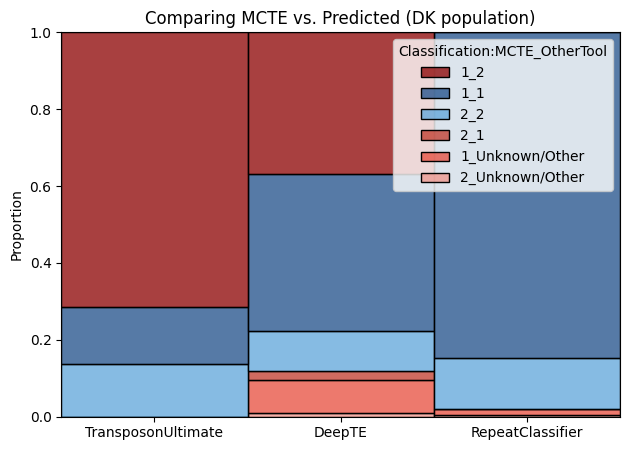

In [ ]:
#Finally make the plot :D
palette = [
    "#8B0000",  
    "#1D4E89",  
    "#5DA5DA",  
    "#C0392B",  
    "#E74C3C",  
    "#F1948A"
]
sns.histplot(data=final,x="Tool",hue = "Classification:MCTE_OtherTool", stat = "count", multiple = "fill", palette = palette)
plt.ylabel("Proportion")
plt.xlabel(" ")
plt.tight_layout()
plt.title("Comparing MCTE vs. Predicted (DK population)")
plt.tight_layout()
plt.savefig("SuppFigure_ClusteringWithMCTE.jpg")